# E90: Which of the labels we assumed on the old 67M tasks survive the frozen definition?

**Provisional: no independent check has run.**

## The answer

Only one old label holds through a named mechanism: copying at a new marker runs through the original model's copying head, and its lookup twin does not. Removing directions does not tell new from old: tasks built to be new read "reuses", and the map built to be old reads unreadable by a hair. Tasks labelled as strengthening what the model already does get no reading, apart from the copy tasks.

Throughout, a circuit built from old parts reads as reuse.


## What we were trying to test

We have called old fine-tunes of the 67M "new" or "existing" for weeks, nearly always by how the task was built. The user froze one definition, and this run reads the old tasks under it. Its verdict is relative to a named capability C, a text rule the original model W₀ can be read to compute: "reuses C", "not through C", or "unreadable". There is no unqualified "new".

For each task we ask whether C could carry it at all: does a small map from C's value to the answer, fitted on half the keys, beat the most common answer on the other half? That needs no fine-tuned state.

Then we remove C and measure the **share**: the mean log-odds the state loses, minus what W₀ loses on the same windows, over the state's log-odds gain. Zero means the removal cost nothing beyond W₀'s loss, and one means the whole gain went. The reference is a **band**: the same share under 20 random removals of the same size.

A loss alone could just mean the removal hit the answer. So each verdict also reads a **spared control** on the same windows. Where a mechanism is located, it is the other task. Otherwise it is a **hand write**: a weight change inside block 1's MLP that sends each key straight to its answer, scaled to the state's gain. State above the band and control within reads "reuses C". State within and control above reads "not through C". Both above reads "not specific", and both within reads "does not reach".


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/new_vs_reuse/figures")


## What we expected, and why

The plan expected the copying pair to read as assumed, since a real mechanism is located there. It leaned to "not specific" on the map built from W₀'s own top guess, because a write of those answers should lie in the removed directions. It expected "not specific" on the copy and random maps too, each losing about all the gain. It expected "does not apply" on every task with a constant answer, because a constant needs no capability.

## The table

One line per old task. The first verdict is my presentation, not the filing: where the capability does not count by the admissibility test, I lead with "no C listed" and give the removal's read beside it. The filed table in `stage2.json` is unedited. The report adds a column naming the old finding that rested on each label.

| Old task | Assumed | Verdict | Read beside it | Why unreadable |
|---|---|---|---|---|
| Copy at a marker, in context | reuses | **reuses C**, 0.47-0.56 | lookup about 0, band 0.21; earlier verdict "mixed" stands | |
| Lookup at the same marker | new | **no C listed** | not through C, about 0 | |
| Rank-1 map | old | **not specific** | 0.16-0.22, write 0.047, band 0.027 | its write leaves the band by 0.02 |
| Cipher, same keys | new | **no C listed** | reuses C, 0.08-0.12, write -0.033 | |
| Half-known map | half-known | **reuses C**, one key admits it | 0.13-0.14, write about -0.04 | |
| Copy, 32 keys | strengthens | **reuses C** | 0.50-0.53, write -0.043, band 0.053 | |
| Copy, 24 keys | reuses | **reuses C** | 0.66-0.68, write -0.125, band 0.038 | |
| Random map, 32 keys | new | **no C listed** | reuses C, 0.36-0.37, write 0.007 | |
| Lowercase; emoticon; ladder; many cues; one-key random map | existing, or new for the last | **does not apply** | | a constant answer |
| 50- and 500-word ciphers; prior-matched cipher; shuffled half-known map | new | **no C listed** | | |
| Class map; its twin | open | **admissible, not read**; **no C listed, not read** | | a later pass |
| Code-like text; narrow lowercase | none; performed | **excluded** | | learned nothing; never trained |
| Ladder table at " which" | existing | **gap** | " was" is W₀'s top-1 on 316 of 4,000 windows | no key kept the target |
| Emoticon table at " :" | existing | **gap** | "o" is top-1 on 0 of 2,880 windows | no key kept the target |
| Two-sided lowercase | existing | **not specific** | state 0.087, push 0.031, band 0.011 | the push leaves the band |
| Ladder push | existing | **does not reach** | state -0.003, push -0.049, band 0.009 | neither loses |

## What we observed

### Does one row read as assumed through a located mechanism?


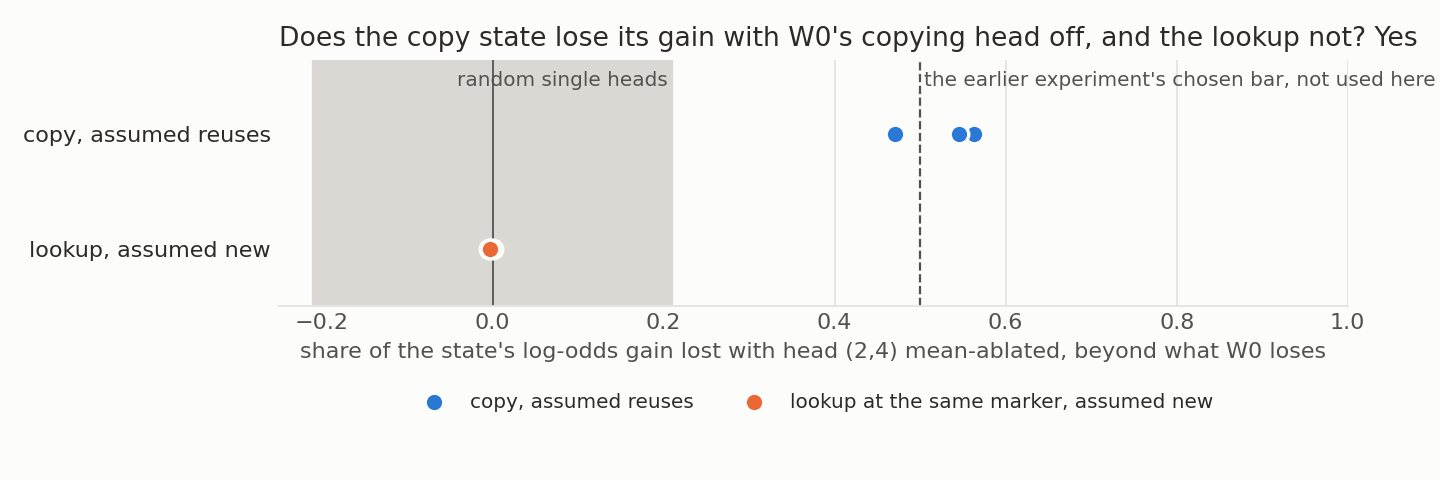

In [2]:
display(Image(FIG / "mechanism.png", width=800))


**Reading it.** Yes, one. With the original model's copying head, (2,4), off, the copy state loses 0.47 to 0.56 of its gain, and the lookup state nothing, where random single heads reach 0.21. The grey band is the random heads, and the dashed bar belongs to the earlier experiment, whose filed verdict "mixed" stands beside this. The caveat: at the marker the original model barely gives this answer, and the head moves it only a little, so the head's part in this task is largely built by the fine-tune.

### Does the verdict under direction removal separate new from old?


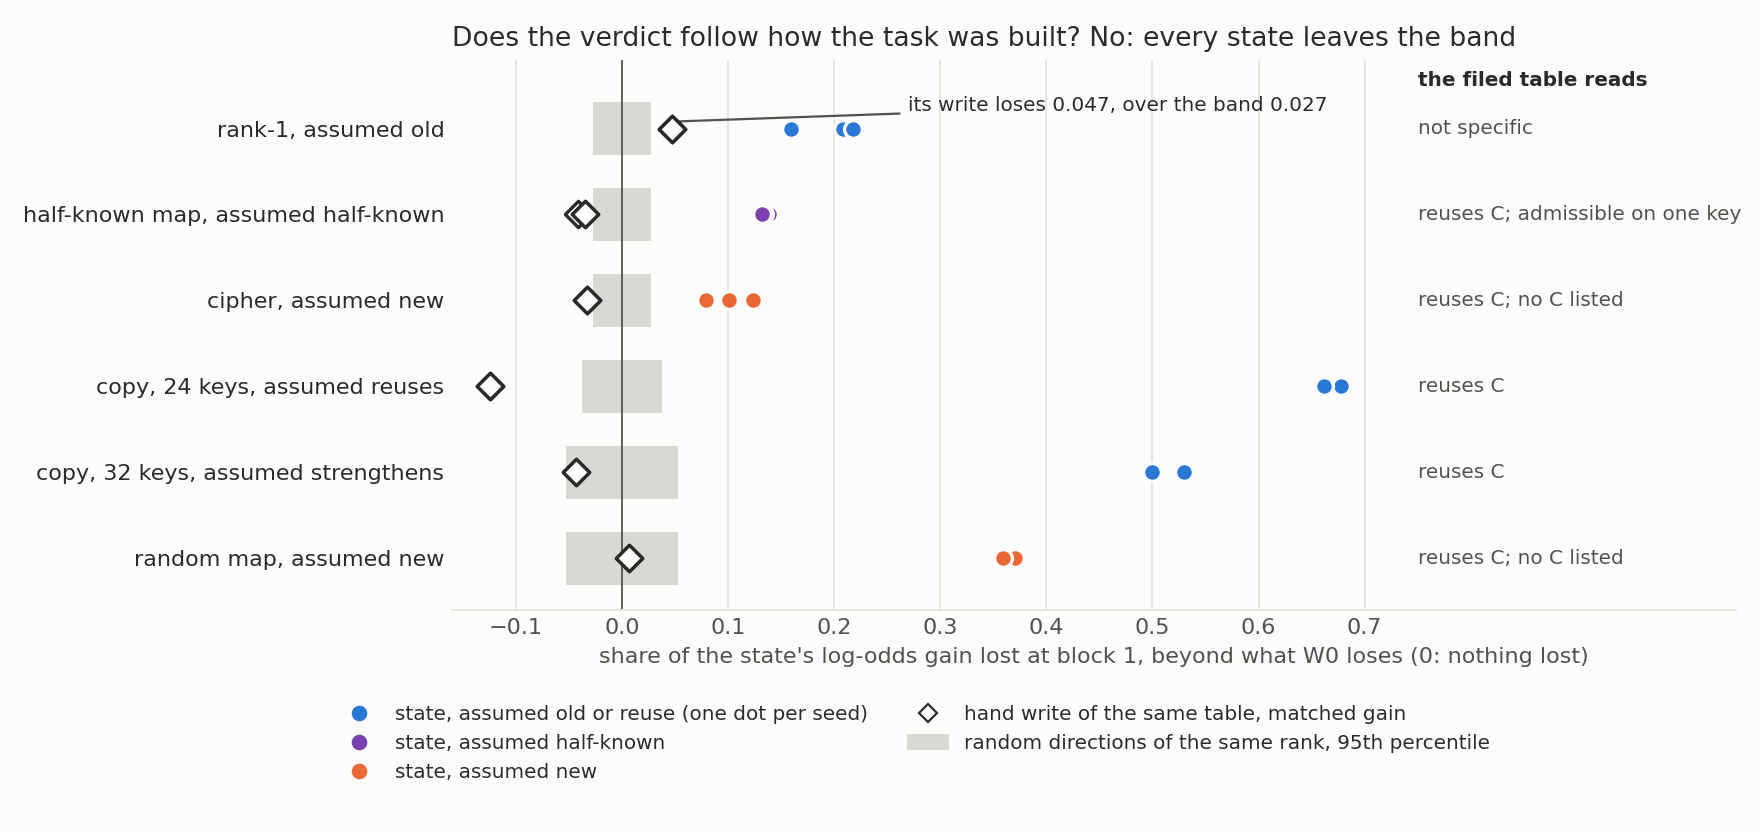

In [3]:
display(Image(FIG / "value_form.png", width=950))


**Reading it.** No. Every state leaves its grey band, the cipher and random map included, both built to be new. The diamonds are the hand writes, and only one leaves the band: the rank-1 write, at 0.047 over 0.027. That margin of 0.02, from one write, is all that makes the row built to be old read unreadable while the cipher reads "reuses". The filing expected "not specific" on the copy and random maps; they read "reuses", a reversed lean, not refiled.

The cipher and random map have no listed capability by the admissibility test, each a tie at zero. The half-known map's capability counts only because one key of twelve happens to share W₀'s guess. So the removal's reading on these rows shows what the removal does, not a label.

The code says why the write is spared. The removal acts on block 1's output, and the write sits inside block 1, so the write has already read its key and survives unless its answer direction lies in the removed directions. So a spared write shows that a state's loss is not merely a lost answer direction. It does not show the state uses the capability for more than needing the token: the random map needs the token to find its key.

### Do the shares follow the assumed labels, even though the verdicts do not?


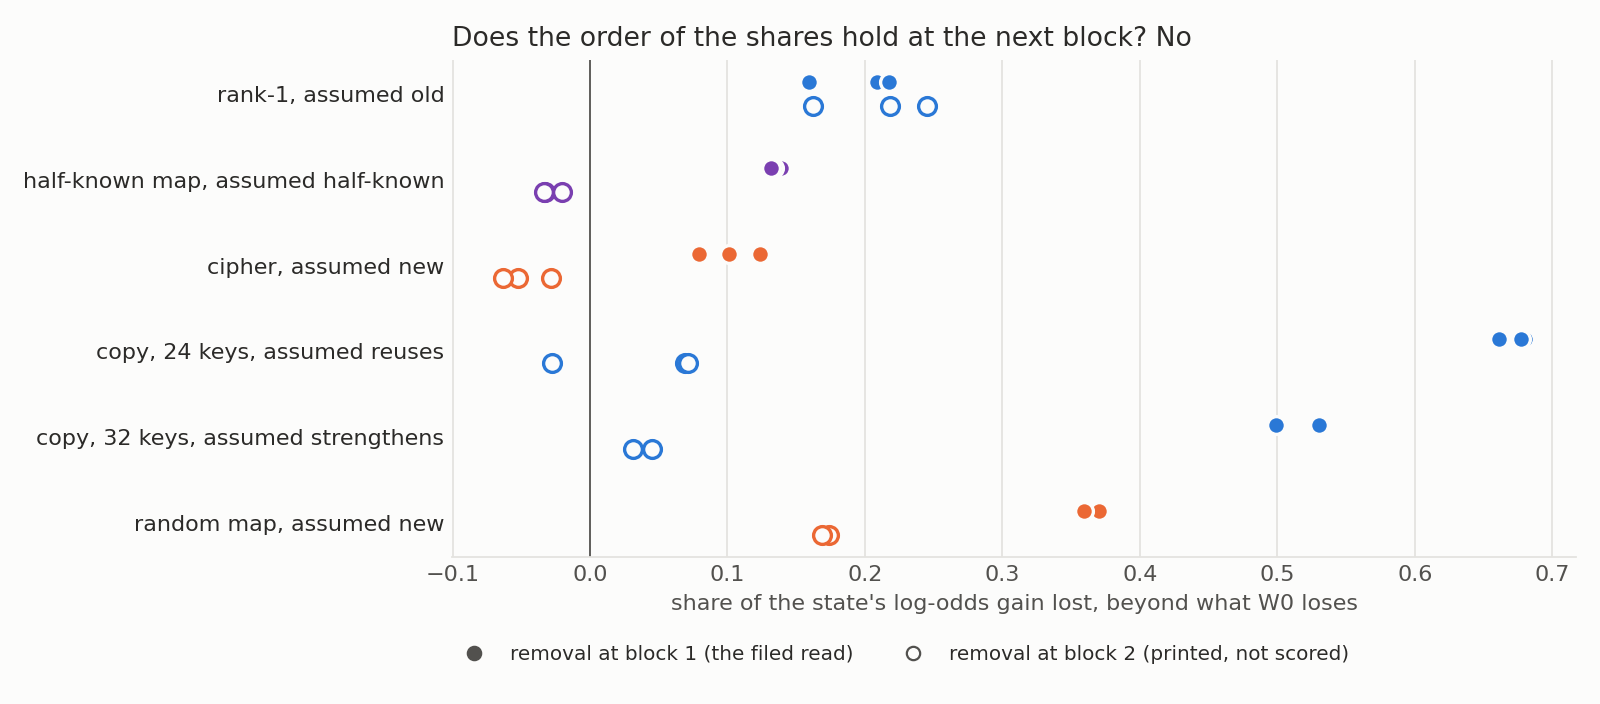

In [4]:
display(Image(FIG / "blocks.png", width=900))


**Reading it.** At block 1 yes, as a pattern we did not file, so it is exploratory and not a result. The filled dots order rank-1 over the half-known map over the cipher, and copy over the random map, though the middle gap is under 0.01. The hollow dots are block 2, printed and not scored: the random map passes the 32-key copy map there, and the half-known map and cipher go negative. Two copy tasks also differ by as much as rank-1 and the cipher do. A filed comparison on new seeds or tasks would test it.

### Is the strengthening side read?


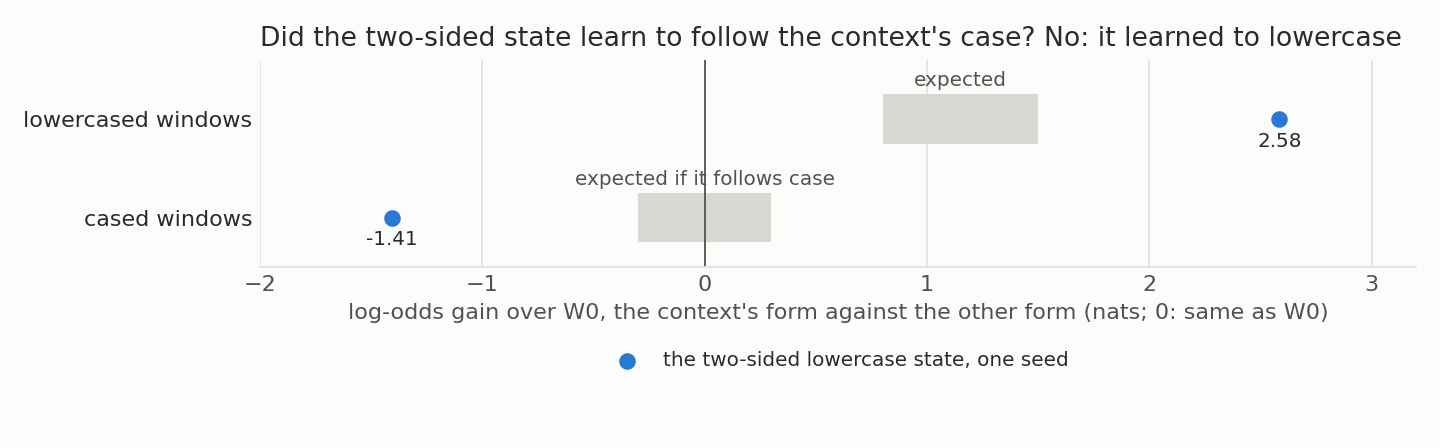

In [5]:
display(Image(FIG / "lowercase.png", width=800))


**Reading it.** No. The two-sided lowercase state gained 2.58 on lowercased windows and fell 1.41 on cased ones, against the grey ranges expected of a task that follows case: it learned mainly to lowercase, so it is not the task it was built to be. It reads "not specific" besides. The input-dependent ladder and emoticon never reached a state, because the original model's top guess at the trigger is almost never the old target. The ladder push reads "does not reach". The constant-answer tasks read "does not apply". So every row labelled existing, apart from the copy tasks, has no reading, and even the copy tasks read as the random map does.

## What we learned

The definition backs one old label through a mechanism, and the earlier filed verdict on that label stays "mixed". Elsewhere on the 67M, "new" and "old" remain assumptions: the removal's verdict separates neither, and the admissibility test, not the removal, is what stops new-by-construction rows reading "reuses". The second question in `GOALS.md` needs "existing" read, and it is not, beyond copying. The Qwen check, `reports/analyses/2026-11-05_analysis_e90-qwen-check.md`, finds the definition writes on the template only.

## How compelling is the evidence

Value-form rows have two or three seeds and one write per table, and they rest on block 1 alone, where W₀'s guess is possessed at 0.777 against a 0.75 bar. Token identity's control is weak: it shows W₀'s output depends on these directions more than on random ones, and those directions hold 0.64 of the variance against 0.04, unmatched. The tasks covered are those in the table, one format each. The removal is blind to a new circuit from old parts.

## Surprises

**Something unexpected happened that I cannot fully explain.** We filed "not specific" on the copy and random maps with shares about 1, and read "reuses" with shares 0.50 and 0.37. The code explains the spared write, not those sizes or the flip at block 2.

## What next

Nothing is proposed here: the lead batches changes to the definition. The report closes with the plain questions the table leaves open: what counts as evidence of strengthening on a constant answer, which capability removes more than the need for the token, and how large a share must be.

## Scorecard

| id | claim | filed | read | verdict |
|---|---|---|---|---|
| A6 | half-known map, W₀'s guess | not admissible | 0.083 against 0 | miss |
| R2 | copy, random map, write | not specific | reuses C | miss, a reversed lean |
| R3 | rank-1 and its write | not specific | not specific | as filed |
| R5 | copy, lookup under the head | reuses; not through | same | as filed |
| R7 | ladder push | not specific | does not reach | miss |
| I1, I2 | input-dependent tables | a gap as a branch | no version kept the target | branch |
| I3 | two-sided lowercase | not specific | not specific | as filed |

The other rows, all as filed, are in the report.

## Not run

An independent check; the class map and its twin; admissibility on the readout's values; the second 32-key copy and random tasks; further seeds of the two-sided lowercase and the ladder push; the overlap of each write with the removed directions; new seeds for the graded order; Qwen.

Results `experiments/new_vs_reuse/results/`; MATS `debug`, one L40, $0, jobs 52317, 52350, 52363. Full record: `reports/analyses/2026-11-05_analysis_e90-old-labels.md`. Departures from the literature: the report's list, chiefly that the capability is read on natural text and removed on marker windows, and that removal, not pruning, is the label.
